In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
from scipy import stats
import matplotlib.pyplot as plt

In [103]:

pd.options.display.float_format = '{:,.2f}'.format

In [104]:
df = pd.read_csv("Sell (Cleaned).csv")

In [134]:
df

,property_type,completion_status,title,price_egp,city,town,district,lat,lon,bedrooms,...,listed_date,payment_method,description,agent_id,broker_id,area_status,price_per_sqm,price_zscore,area_zscore,price_per_sqm_zscore
0,Duplex,completed,Garden Villa - Lake View Boutique - Prime Loca...,"24,500,000.00",Cairo,New Cairo City,The 5th Settlement,30.04,31.53,3,...,2026-03-03 19:15:06+00:00,cash,Garden Villa for Sale – Featured in Lake View ...,58866,5758,Original,"55,056.18",0.24,0.25,-0.21
1,Apartment,off_plan,For Sale: Finished Apartment+ ACs in Village West,"5,145,000.00",Giza,Sheikh Zayed City,Sheikh Zayed Compounds,30.05,31.02,2,...,2026-03-04 11:24:23+00:00,cash,For Sale: Finished Apartment with ACs in Villa...,67166,492,Original,"41,829.27",-0.35,-0.12,-0.37
2,Apartment,completed,UnderMarket Price for Apt. 250 RTM PrimeLocation,"10,800,000.00",Cairo,New Cairo City,The 5th Settlement,30.01,31.58,4,...,2026-03-04 14:03:51+00:00,cash,Palm Hills New Cairo Apartment BUA: 250sqm 4 B...,47158,5279,Original,"43,200.00",-0.18,0.03,-0.35
3,Apartment,completed,lowest price 2bds fullyfurnished @ lake view,"10,500,000.00",Cairo,New Cairo City,The 5th Settlement,30.03,31.54,2,...,2026-03-04 12:38:11+00:00,cash,Lake View Residence 136 sqm Fully Finished Ren...,63401,5758,Original,"77,205.88",-0.18,-0.10,0.06
4,Villa,completed,Exclusive Type M with Lowest Price RTM in PNC,"19,500,000.00",Cairo,New Cairo City,The 5th Settlement,30.01,31.58,4,...,2026-03-03 09:45:41+00:00,cash,Palm Hills New Cairo Type M BUA: 255sqm LAND: ...,47158,5279,Original,"76,470.59",0.09,0.03,0.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18345,Apartment,completed,Ready to Move Apartment in Mountain View iCity,"4,200,000.00",Giza,6 October City,6 October Compounds,30.01,30.93,2,...,2026-02-27 12:52:54+00:00,installments,Ready to Move Resale Apartment in Mountain Vie...,70243,5509,Original,"32,307.69",-0.37,-0.11,-0.49
18346,Twin House,completed_primary,"261sqm Villa Palm Hills, Ready to Move In","6,700,000.00",Giza,6 October City,6 October Compounds,29.96,30.92,3,...,2026-02-27 12:52:20+00:00,cash | installments,Own Your Villa Immediately in the Prime Area o...,67568,6126,Original,"134,000.00",-0.30,-0.20,0.76
18347,Apartment,completed,Ground floor apartment with private garden for...,"7,000,000.00",Cairo,Madinaty,Privado,30.09,31.67,3,...,2026-02-27 12:52:18+00:00,cash,Ground floor apartment with private garden for...,69259,6229,Original,"56,000.00",-0.29,-0.12,-0.20
18348,Twin House,completed_primary,278m Villa Ready to View in Palm Hills Plateau,"7,000,000.00",Giza,6 October City,6 October Compounds,29.96,30.92,3,...,2026-02-27 12:51:37+00:00,cash | installments,Own Your Villa Immediately in the Prime Area o...,67568,6126,Original,"140,000.00",-0.29,-0.20,0.83


In [138]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18350 entries, 0 to 18349
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   property_type         18349 non-null  object  
 1   completion_status     18312 non-null  object  
 2   title                 18349 non-null  object  
 3   price_egp             18349 non-null  float64 
 4   city                  18349 non-null  object  
 5   town                  18349 non-null  object  
 6   district              18349 non-null  object  
 7   lat                   18349 non-null  float64 
 8   lon                   18349 non-null  float64 
 9   bedrooms              18320 non-null  category
 10  bathrooms             18322 non-null  category
 11  area_value            18349 non-null  float64 
 12  furnished             10719 non-null  object  
 13  listing_level         18349 non-null  object  
 14  listed_date           18349 non-null  object  
 15  pa

In [139]:
bed_order = ['studio', '1', '2', '3', '4', '5', '6', '7', '7+']
bath_order = ['none', '1', '2', '3', '4', '5', '6', '7', '7+']

for sell in [df]:
    df['bedrooms'] = pd.Categorical(df['bedrooms'], categories=bed_order, ordered=True)
    df['bathrooms'] = pd.Categorical(df['bathrooms'], categories=bath_order, ordered=True)

In [140]:
print(f"\n DATA TYPES:")
print(df.dtypes)


 DATA TYPES:
property_type             object
completion_status         object
title                     object
price_egp                float64
city                      object
town                      object
district                  object
lat                      float64
lon                      float64
bedrooms                category
bathrooms               category
area_value               float64
furnished                 object
listing_level             object
listed_date               object
payment_method            object
description               object
agent_id                   int64
broker_id                  int64
area_status               object
price_per_sqm            float64
price_zscore             float64
area_zscore              float64
price_per_sqm_zscore     float64
dtype: object


In [108]:
df.describe()

,price_egp,lat,lon,area_value,agent_id,broker_id,price_per_sqm
count,"18,349.00","18,349.00","18,349.00","18,349.00","18,350.00","18,350.00","18,349.00"
mean,"16,581,272.62",29.91,31.27,227.61,"56,478.68","3,594.18","72,018.77"
std,"33,023,830.46",0.83,1.14,873.63,"16,084.66","3,241.28","81,684.74"
min,"340,000.00",25.07,25.48,21.00,-1.00,-1.00,"1,092.47"
25%,"5,700,000.00",29.99,30.99,130.00,"48,325.00","1,168.00","39,322.03"
50%,"9,800,000.00",30.03,31.47,175.00,"60,061.50","4,173.00","61,224.49"
75%,"18,000,000.00",30.07,31.59,250.00,"70,202.00","5,811.00","89,433.57"
max,"1,000,000,000.00",31.50,34.90,"96,600.00","73,845.00","179,955.00","4,710,144.93"


In [109]:
print(f"\n UNIQUE VALUES PER COLUMN:")
for col in df.columns:
    unique_count = df[col].nunique(dropna=False)
    print(f" - {col}: {unique_count} unique values")


 UNIQUE VALUES PER COLUMN:
 - property_type: 18 unique values
 - completion_status: 5 unique values
 - title: 16448 unique values
 - price_egp: 4148 unique values
 - city: 13 unique values
 - town: 62 unique values
 - district: 473 unique values
 - lat: 1412 unique values
 - lon: 1415 unique values
 - bedrooms: 10 unique values
 - bathrooms: 10 unique values
 - area_value: 688 unique values
 - furnished: 4 unique values
 - listing_level: 4 unique values
 - listed_date: 16575 unique values
 - payment_method: 4 unique values
 - description: 16670 unique values
 - agent_id: 2125 unique values
 - broker_id: 660 unique values
 - area_status: 2 unique values
 - price_per_sqm: 9340 unique values


In [110]:
price_stats = pd.Series(
    {
        "(Mean)": df["price_egp"].mean(),
        "(Median)": df["price_egp"].median(),
        "(Std Dev)": df["price_egp"].std(),
        "(Min)": df["price_egp"].min(),
        "(Max)": df["price_egp"].max(),
    }
)

price_stats.apply(lambda x: f"{x:,.2f}")

(Mean)          16,581,272.62
(Median)         9,800,000.00
(Std Dev)       33,023,830.46
(Min)              340,000.00
(Max)        1,000,000,000.00
dtype: object

In [141]:
area_value = pd.Series(
    {
        "(Mean)": df["area_value"].mean(),
        "(Median)": df["area_value"].median(),
        "(Std Dev)": df["area_value"].std(),
        "(Min)": df["area_value"].min(),
        "(Max)": df["area_value"].max(),
    }
)

area_value.apply(lambda x: f"{x:,.2f}")

(Mean)          227.61
(Median)        175.00
(Std Dev)       873.63
(Min)            21.00
(Max)        96,600.00
dtype: object

In [142]:
price_per_sqm = pd.Series(
    {
        "(Mean)": df["price_per_sqm"].mean(),
        "(Median)": df["price_per_sqm"].median(),
        "(Std Dev)": df["price_per_sqm"].std(),
        "(Min)": df["price_per_sqm"].min(),
        "(Max)": df["price_per_sqm"].max(),
    }
)


price_per_sqm.apply(lambda x: f"{x:,.2f}")

(Mean)          72,018.77
(Median)        61,224.49
(Std Dev)       81,684.74
(Min)            1,092.47
(Max)        4,710,144.93
dtype: object

In [111]:
Q1 = df["price_egp"].quantile(0.25)
print("Q1:", Q1)           # 25%  الربع الاول

Q1: 5700000.0


In [112]:
Q3 = df["price_egp"].quantile(0.75)
print("Q3:", Q3)        # 75%  الربع الثالث

Q3: 18000000.0


# IQR

In [113]:
IQR = Q3 - Q1
print("IQR:", IQR)

IQR: 12300000.0


In [114]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR                  # كشف" ال outliers" 

print("Lower Bound:", lower)           # range
print("Upper Bound:", upper)

Lower Bound: -12750000.0
Upper Bound: 36450000.0


In [115]:
outliers = df[
    (df["price_egp"] < lower) |
    (df["price_egp"] > upper)
]

outliers

,property_type,completion_status,title,price_egp,city,town,district,lat,lon,bedrooms,...,area_value,furnished,listing_level,listed_date,payment_method,description,agent_id,broker_id,area_status,price_per_sqm
10,Villa,completed,lowest type B villa ready to move at Palm hills,"47,000,000.00",Cairo,New Cairo City,The 5th Settlement,30.01,31.58,6,...,963.00,NaN,premium,2026-03-03 13:11:43+00:00,cash,Palm Hills New Cairo Type B BUA:607 LAND: 963 ...,67498,5279,Original,"48,805.82"
11,Twin House,completed,Twinhouse in Levana with Smart System,"37,000,000.00",Cairo,El Khalifa,Al Abageyah,30.02,31.29,5,...,320.00,NO,premium,2026-03-02 04:25:37+00:00,cash,Uptown cairo - levana Twinhouse for sale ready...,63799,5758,Original,"115,625.00"
15,Villa,completed,Standalone Villa for Sale in Swan Lake Residence,"85,000,000.00",Cairo,New Cairo City,The 5th Settlement,30.07,31.47,5,...,652.00,NaN,premium,2026-03-04 13:42:17+00:00,cash,Standalone Villa for Sale in Swan Lake Residen...,69876,6313,Original,"130,368.10"
20,Villa,completed,Luxury Standalone Villa For Sale Limited Offer,"63,000,000.00",North Coast,Qesm Marsa Matrouh,Silver Sands,31.27,27.38,6,...,304.00,PARTLY,premium,2026-03-04 13:08:58+00:00,cash,Project Name : Silversands Developer Name : Or...,18382,85,Original,"207,236.84"
25,Villa,completed,Villa First row golf - Under market price,"191,000,000.00",Cairo,New Cairo City,El Katameya,29.99,31.40,7,...,850.00,NO,premium,2026-03-04 13:15:04+00:00,cash,Katameya Heights 1st row golf standalone For S...,67405,128,Original,"224,705.88"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18306,Villa,completed,Very Prime Location Villa For Sale In The Estates,"46,000,000.00",Giza,Sheikh Zayed City,Sheikh Zayed Compounds,30.08,30.88,4,...,433.00,NaN,standard,2026-02-27 13:48:34+00:00,cash,Very Prime Location Villa For Sale In The Esta...,44150,4915,Original,"106,235.57"
18307,Twin House,completed,Very Prime Location Twin House For Sale In The...,"47,500,000.00",Giza,Sheikh Zayed City,Sheikh Zayed Compounds,30.08,30.88,4,...,295.00,NaN,standard,2026-02-27 13:48:33+00:00,cash,Very Prime Location Twin House For Sale In The...,44150,4915,Original,"161,016.95"
18309,Villa,completed,Very Prime Location Villa For Sale In The Estat,"106,000,000.00",Giza,Sheikh Zayed City,Sheikh Zayed Compounds,30.08,30.88,4,...,636.00,NaN,standard,2026-02-27 13:46:01+00:00,cash,Very Prime Location Villa For Sale In The Esta...,44150,4915,Original,"166,666.67"
18311,Villa,completed,Very Prime Location Villa For Sale In The Estate,"120,000,000.00",Giza,Sheikh Zayed City,Sheikh Zayed Compounds,30.08,30.88,4,...,636.00,NaN,standard,2026-02-27 13:45:58+00:00,cash,Very Prime Location Villa For Sale In The Esta...,44150,4915,Original,"188,679.25"


In [116]:
property_types = outliers["property_type"].value_counts().reset_index()

property_types.columns = ["Property Type", "Count"]

property_types

,Property Type,Count
0,Villa,1160
1,Twin House,114
2,Townhouse,49
3,Apartment,35
4,Whole Building,14
5,Land,13
6,Chalet,11
7,Palace,8
8,Hotel Apartment,7
9,Duplex,4


In [117]:
apartment_outliers = df[
    (df["property_type"] == "Apartment") &
    (
        (df["price_egp"] < lower) |
        (df["price_egp"] > upper)
    )
]

apartment_outliers[["property_type", "price_egp"]]

,property_type,price_egp
653,Apartment,"39,000,000.00"
2451,Apartment,"42,300,000.00"
2521,Apartment,"42,824,700.00"
3291,Apartment,"52,000,000.00"
3649,Apartment,"55,530,000.00"
4357,Apartment,"48,000,000.00"
5094,Apartment,"39,300,000.00"
5095,Apartment,"39,300,300.00"
5096,Apartment,"39,400,000.00"
5390,Apartment,"45,000,000.00"


In [118]:
outlier_prices = df.loc[
    (df["price_egp"] < lower) |
    (df["price_egp"] > upper),
    ["price_egp"]
].reset_index()

outlier_prices                 # هنا سعر الصنف

,index,price_egp
0,10,"47,000,000.00"
1,11,"37,000,000.00"
2,15,"85,000,000.00"
3,20,"63,000,000.00"
4,25,"191,000,000.00"
...,...,...
1413,18306,"46,000,000.00"
1414,18307,"47,500,000.00"
1415,18309,"106,000,000.00"
1416,18311,"120,000,000.00"


In [119]:
Q1_area = df["area_value"].quantile(0.25)
Q3_area = df["area_value"].quantile(0.75)

IQR_area = Q3_area - Q1_area

lower_area = Q1_area - 1.5 * IQR_area
upper_area = Q3_area + 1.5 * IQR_area

outlier_area = df.loc[
    (df["area_value"] < lower_area) |
    (df["area_value"] > upper_area),
    ["area_value"]
]

outlier_area                              # هنا دا سعر الارض كامل       

,area_value
0,445.00
10,963.00
15,652.00
25,850.00
34,575.00
...,...
18286,600.00
18306,433.00
18309,636.00
18310,550.00


In [120]:
Q1_price_per_sqm = df["price_per_sqm"].quantile(0.25)
Q3_price_per_sqm = df["price_per_sqm"].quantile(0.75)

IQR_price_per_sqm = Q3_price_per_sqm - Q1_price_per_sqm

lower_price_per_sqm = Q1_price_per_sqm - 1.5 * IQR_price_per_sqm
upper_price_per_sqm = Q3_price_per_sqm+ 1.5 * IQR_price_per_sqm

outlier_price_per_sqm = df.loc[
    (df["price_per_sqm"] < lower_price_per_sqm) |
    (df["price_per_sqm"] > upper_price_per_sqm),
    ["price_per_sqm"]
]

outlier_price_per_sqm                        #  هنا دا بتاع سعر المتر

,price_per_sqm
20,"207,236.84"
25,"224,705.88"
51,"180,000.00"
210,"300,000.00"
255,"209,145.90"
...,...
18250,"657,894.74"
18269,"400,000.00"
18274,"200,000.00"
18309,"166,666.67"


In [121]:
# Create the outlier mask for the 3 columns

outlier_mask = (
    (df["price_egp"] < lower) | (df["price_egp"] > upper) |
    (df["area_value"] < lower_area) | (df["area_value"] > upper_area) |
    (df["price_per_sqm"] < lower_price_per_sqm) |
    (df["price_per_sqm"] > upper_price_per_sqm)
)


# Create table containing all outliers

all_outliers = df.loc[
    outlier_mask,
    ["price_egp", "area_value", "price_per_sqm"]
].copy()


# Identify the reason for each outlier

all_outliers["price_outlier"] = (
    (all_outliers["price_egp"] < lower) |
    (all_outliers["price_egp"] > upper)
)

all_outliers["area_outlier"] = (
    (all_outliers["area_value"] < lower_area) |
    (all_outliers["area_value"] > upper_area)
)

all_outliers["price_per_sqm_outlier"] = (
    (all_outliers["price_per_sqm"] < lower_price_per_sqm) |
    (all_outliers["price_per_sqm"] > upper_price_per_sqm)
)

all_outliers

,price_egp,area_value,price_per_sqm,price_outlier,area_outlier,price_per_sqm_outlier
0,"24,500,000.00",445.00,"55,056.18",False,True,False
10,"47,000,000.00",963.00,"48,805.82",True,True,False
11,"37,000,000.00",320.00,"115,625.00",True,False,False
15,"85,000,000.00",652.00,"130,368.10",True,True,False
20,"63,000,000.00",304.00,"207,236.84",True,False,True
...,...,...,...,...,...,...
18307,"47,500,000.00",295.00,"161,016.95",True,False,False
18309,"106,000,000.00",636.00,"166,666.67",True,True,True
18310,"27,800,000.00",550.00,"50,545.45",False,True,False
18311,"120,000,000.00",636.00,"188,679.25",True,True,True


In [122]:
from scipy import stats

df["price_zscore"] = stats.zscore(df["price_egp"])

In [123]:
df[["price_egp", "price_zscore"]]

,price_egp,price_zscore
0,"24,500,000.00",NaN
1,"5,145,000.00",NaN
2,"10,800,000.00",NaN
3,"10,500,000.00",NaN
4,"19,500,000.00",NaN
...,...,...
18345,"4,200,000.00",NaN
18346,"6,700,000.00",NaN
18347,"7,000,000.00",NaN
18348,"7,000,000.00",NaN


In [124]:
df["price_egp"].isna().sum()    # في سعر وحده مفقوده

np.int64(1)

In [125]:
df[df["price_egp"].isna()]             # الصف ال في السعر المفقود

,property_type,completion_status,title,price_egp,city,town,district,lat,lon,bedrooms,...,furnished,listing_level,listed_date,payment_method,description,agent_id,broker_id,area_status,price_per_sqm,price_zscore
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,-1,-1,Original,NaN,NaN


In [126]:
from scipy import stats

df["price_zscore"] = stats.zscore(
    df["price_egp"],
    nan_policy="omit"
)

df["area_zscore"] = stats.zscore(
    df["area_value"],
    nan_policy="omit"
)

df["price_per_sqm_zscore"] = stats.zscore(
    df["price_per_sqm"],
    nan_policy="omit"
)

In [127]:
df[
    [
        "price_egp",
        "price_zscore",
        "area_value",
        "area_zscore",
        "price_per_sqm",
        "price_per_sqm_zscore"
    ]
]

,price_egp,price_zscore,area_value,area_zscore,price_per_sqm,price_per_sqm_zscore
0,"24,500,000.00",0.24,445.00,0.25,"55,056.18",-0.21
1,"5,145,000.00",-0.35,123.00,-0.12,"41,829.27",-0.37
2,"10,800,000.00",-0.18,250.00,0.03,"43,200.00",-0.35
3,"10,500,000.00",-0.18,136.00,-0.10,"77,205.88",0.06
4,"19,500,000.00",0.09,255.00,0.03,"76,470.59",0.05
...,...,...,...,...,...,...
18345,"4,200,000.00",-0.37,130.00,-0.11,"32,307.69",-0.49
18346,"6,700,000.00",-0.30,50.00,-0.20,"134,000.00",0.76
18347,"7,000,000.00",-0.29,125.00,-0.12,"56,000.00",-0.20
18348,"7,000,000.00",-0.29,50.00,-0.20,"140,000.00",0.83


In [128]:
zscore_outliers = df[
    (df["price_zscore"].abs() > 3) |
    (df["area_zscore"].abs() > 3) |
    (df["price_per_sqm_zscore"].abs() > 3)
]

zscore_outliers              #   هنا طلعت القيم البعيده اوي عن الطبيعي وبكدا ال rows قلت جدا عن الطبيعي 

,property_type,completion_status,title,price_egp,city,town,district,lat,lon,bedrooms,...,listed_date,payment_method,description,agent_id,broker_id,area_status,price_per_sqm,price_zscore,area_zscore,price_per_sqm_zscore
25,Villa,completed,Villa First row golf - Under market price,"191,000,000.00",Cairo,New Cairo City,El Katameya,29.99,31.40,7,...,2026-03-04 13:15:04+00:00,cash,Katameya Heights 1st row golf standalone For S...,67405,128,Original,"224,705.88",5.28,0.71,1.87
77,Villa,completed,Architectural Masterpiece the Heart of Lake View,"120,000,000.00",Cairo,New Cairo City,El Katameya,30.00,31.52,7+,...,2026-03-04 11:23:29+00:00,cash,"Land Area: 1,300 m² Built-up Area: 1050 m² Lay...",61710,1435,Original,"114,285.71",3.13,0.94,0.52
200,Villa,completed,KATAMEYA DUNES-SPecial VILLA1400M FIRST ROW GOLF,"137,000,000.00",Cairo,New Cairo City,El Katameya,30.00,31.52,6,...,2026-02-04 12:49:25+00:00,cash,Stand alone in katameya dunnes First row Prime...,20602,1978,Original,"97,857.14",3.65,1.34,0.32
204,Villa,completed,Katameya Dunes - Special Villa1270m First Row ...,"124,000,000.00",Cairo,New Cairo City,El Katameya,30.00,31.52,5,...,2026-03-03 13:00:24+00:00,cash,VILLA FOR SALE IN KATTAMEYA DUNES LAND 1270M B...,20602,1978,Original,"97,637.80",3.25,1.19,0.31
486,Villa,completed,Lowest price in katameya heights good opportunity,"130,000,000.00",Cairo,New Cairo City,El Katameya,29.99,31.40,4,...,2026-02-08 16:28:50+00:00,cash,Katameya heights Standalone for sale Second ro...,39437,741,Original,"144,444.44",3.43,0.77,0.89
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18082,Villa,completed,Luxury 6-Bedroom Standalone Villa – Caesar Sodic,"135,000,000.00",North Coast,Qesm Marsa Matrouh,Caesar,31.09,28.01,6,...,2026-02-27 18:29:08+00:00,cash,Ceaser Sodic North Coast Standalone Villa 2 fl...,67750,128,Original,"271,629.78",3.59,0.31,2.44
18098,Villa,completed,Exclusive Golf & Lake View Villa for Sale in D...,"223,250,000.00",Cairo,New Cairo City,El Katameya,30.00,31.52,7+,...,2026-02-27 18:19:35+00:00,cash,Exclusive Golf & Lake View Villa for Sale in K...,52937,4770,Original,"136,128.05",6.26,1.62,0.78
18250,Villa,completed,Villa sea view ready to move D.P 20% up to 7 y...,"250,000,000.00",North Coast,Ras Al Hekma,June,31.07,28.05,7,...,2026-02-27 14:31:27+00:00,installments,June Sodic - North Coast Full Sea view Standal...,36977,4298,Original,"657,894.74",7.07,0.17,7.17
18269,Villa,completed,First Row Golf Villa At Golf Views | Direct Lake,"240,000,000.00",Giza,6 October City,Cairo Alexandria Desert Road,30.01,31.04,4,...,2026-02-27 14:12:01+00:00,cash,Villa for Sale in Palm Hills Golf Views • Dire...,57493,85,Original,"400,000.00",6.77,0.43,4.02


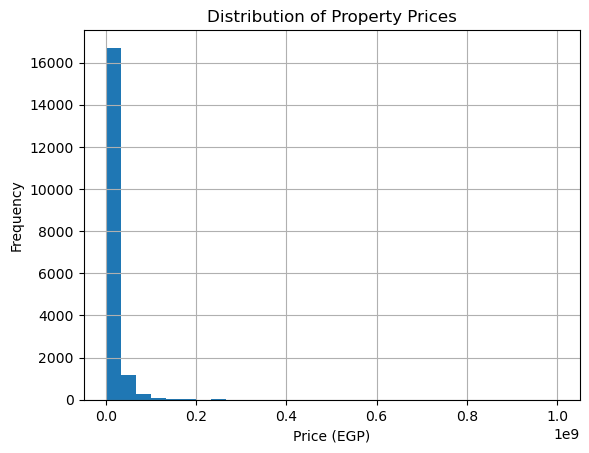

In [129]:
# المحور الأفقي X → نطاقات الأسعار.
#المحور الرأسي Y → عدد العقارات داخل كل نطاق.
 
df["price_egp"].hist(bins=30)

plt.xlabel("Price (EGP)")                         # اختيارييييييييييي
plt.ylabel("Frequency")
plt.title("Distribution of Property Prices")          
plt.show()

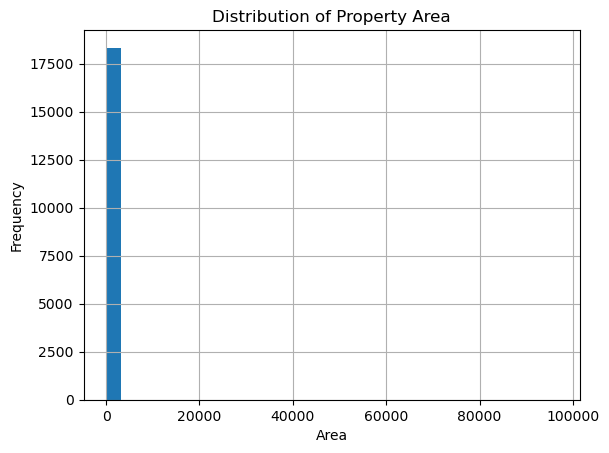

In [130]:
import matplotlib.pyplot as plt

df["area_value"].hist(bins=30)

plt.xlabel("Area")                                      # اختيارييييييييييي
plt.ylabel("Frequency")
plt.title("Distribution of Property Area")
plt.show()

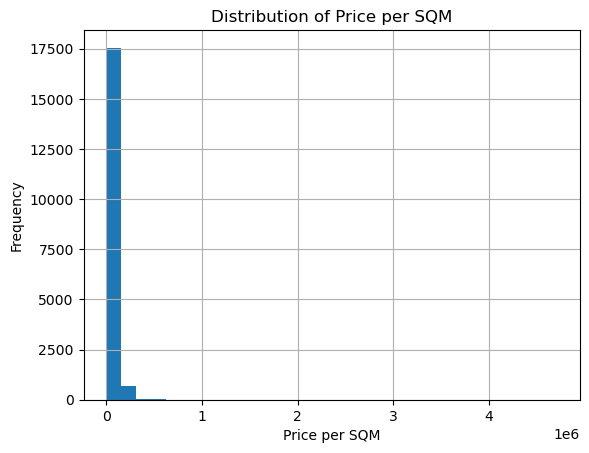

In [131]:
df["price_per_sqm"].hist(bins=30)
                                                               # اختيارييييييييييي
plt.xlabel("Price per SQM")
plt.ylabel("Frequency")
plt.title("Distribution of Price per SQM")
plt.show()